# Household Income Prediction

Predicting annual household income from demographic, spending and asset data.
The data file (Filipino Family Income and Expenditure, Kaggle) is uploaded manually in the loading cell.

In [ ]:
import pandas as pd
from google.colab import files
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [ ]:
needed_columns = [
    # Target Variable
    'Total Household Income',

    # Demographics
    'Household Head Age',
    'Household Head Sex',
    'Household Head Highest Grade Completed',  # Household Head Education
    'Total Number of Family members',
    'Total number of family members employed',

    # Consumption & Expenditures
    'Total Food Expenditure',
    'Education Expenditure',
    'Medical Care Expenditure',
    'Special Occasions Expenditure',
    'Communication Expenditure',
    'Restaurant and hotels Expenditure',
    'Alcoholic Beverages Expenditure',
    'Clothing, Footwear and Other Wear Expenditure',
    'Housing and water Expenditure',
    'Transportation Expenditure',
    'Tobacco Expenditure',
    'Miscellaneous Goods and Services Expenditure',
    'Tobacco Expenditure',
    'Crop Farming and Gardening expenses',


    # Assets & Housing
    'House Floor Area',
    'Number of bedrooms',
    'Electricity',
    'Number of Car, Jeep, Van',
    'Number of Personal Computer',
    'Number of Cellular phone',

    # Employment
    'Household Head Occupation',
    'Household Head Job or Business Indicator',
    'Main Source of Income'
]

In [ ]:
from google.colab import files
import io

uploaded = files.upload()


filename = list(uploaded.keys())[0]


df = pd.read_csv(filename, usecols=needed_columns)


df.head()

Saving Family Income and Expenditure.csv to Family Income and Expenditure.csv


,Total Household Income,Total Food Expenditure,Main Source of Income,Restaurant and hotels Expenditure,Alcoholic Beverages Expenditure,Tobacco Expenditure,"Clothing, Footwear and Other Wear Expenditure",Housing and water Expenditure,Medical Care Expenditure,Transportation Expenditure,...,Household Head Job or Business Indicator,Household Head Occupation,Total Number of Family members,Total number of family members employed,House Floor Area,Number of bedrooms,Electricity,"Number of Car, Jeep, Van",Number of Cellular phone,Number of Personal Computer
0,480332,117848,Wage/Salaries,3000,0,0,4607,63636,3457,4776,...,With Job/Business,General elementary education teaching professi...,4,1,80,3,1,0,2,1
1,198235,67766,Wage/Salaries,2360,960,2132,8230,41370,3520,12900,...,With Job/Business,Transport conductors,3,2,42,2,1,0,3,1
2,82785,61609,Wage/Salaries,4545,270,4525,2735,14340,70,324,...,With Job/Business,Farmhands and laborers,6,3,35,1,0,0,0,0
3,107589,78189,Wage/Salaries,6280,480,0,1390,16638,60,6840,...,With Job/Business,Rice farmers,3,2,30,1,1,0,1,0
4,189322,94625,Wage/Salaries,6400,1040,0,4620,31122,140,6996,...,With Job/Business,General managers/managing proprietors in trans...,4,2,54,3,1,0,3,0


In [ ]:
df.shape

(41544, 28)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 28 columns):
 #   Column                                         Non-Null Count  Dtype 
---  ------                                         --------------  ----- 
 0   Total Household Income                         41544 non-null  int64 
 1   Total Food Expenditure                         41544 non-null  int64 
 2   Main Source of Income                          41544 non-null  object
 3   Restaurant and hotels Expenditure              41544 non-null  int64 
 4   Alcoholic Beverages Expenditure                41544 non-null  int64 
 5   Tobacco Expenditure                            41544 non-null  int64 
 6   Clothing, Footwear and Other Wear Expenditure  41544 non-null  int64 
 7   Housing and water Expenditure                  41544 non-null  int64 
 8   Medical Care Expenditure                       41544 non-null  int64 
 9   Transportation Expenditure                     41544 non-null

**Feature Engineering**






Age Squared- We added Age Squared because income doesn’t grow in a straight line. It helps the model recognize that income changes at different speeds as people get older.

In [ ]:
# Age Squared (Polynomial feature)
df['Head_Age_Squared'] = df['Household Head Age'] ** 2



Crowding Index- Calculated as Family Members / Number of Bedrooms.
High crowding indicates lower socio-economic status, which simple family size alone might miss.


In [ ]:
(df['Number of bedrooms']).min()



0

There are instances with 0 bedrooms, therefore We add 0.001 to the denominator to avoid division by zero.

In [ ]:
# Crowding Index (Ratio)

df['Crowding_Index'] = df['Total Number of Family members'] / (df['Number of bedrooms'] + 0.001)



Employment Rate Ratio - We calculated the ratio of employed family members to the total family size .
The Employment Ratio might be a powerful feature because it measures the economic strength of a household, it tells us how many "mouths to feed" each worker supports.



In [ ]:
# Employment Rate (Ratio)
# we calculate the actual portion of the workers in each family
# This handles cases where teenagers work or adults are unemployed.
df['Employment_Rate'] = (
    df['Total number of family members employed'] /
    df['Total Number of Family members']
)


In [ ]:

expenditure_cols = [
    'Total Food Expenditure',
    'Education Expenditure',
    'Medical Care Expenditure',
    'Special Occasions Expenditure',
    'Communication Expenditure',
    'Restaurant and hotels Expenditure',
    'Alcoholic Beverages Expenditure',
    'Tobacco Expenditure',
    'Clothing, Footwear and Other Wear Expenditure',
    'Housing and water Expenditure',
    'Transportation Expenditure',
    'Miscellaneous Goods and Services Expenditure',
    'Crop Farming and Gardening expenses'
]

df['total_expenditures'] = df[expenditure_cols].sum(axis=1, min_count=1)




Food Ratio -  measures the percentage of total spending dedicated to food. Our logic is that lower income households are more likely to spend a larger portion of their budget on basic needs like food compared to wealthier families, what might make this ratio a strong predictor of total income.

In [ ]:
# Food Expenditure (Ratio)
df['food_ratio'] = df['Total Food Expenditure'] / df['total_expenditures']



In [ ]:
df.head()

,Total Household Income,Total Food Expenditure,Main Source of Income,Restaurant and hotels Expenditure,Alcoholic Beverages Expenditure,Tobacco Expenditure,"Clothing, Footwear and Other Wear Expenditure",Housing and water Expenditure,Medical Care Expenditure,Transportation Expenditure,...,Number of bedrooms,Electricity,"Number of Car, Jeep, Van",Number of Cellular phone,Number of Personal Computer,Head_Age_Squared,Crowding_Index,Employment_Rate,total_expenditures,food_ratio
0,480332,117848,Wage/Salaries,3000,0,0,4607,63636,3457,4776,...,3,1,0,2,1,2401,1.332889,0.250000,297030,0.396755
1,198235,67766,Wage/Salaries,2360,960,2132,8230,41370,3520,12900,...,2,1,0,3,1,1600,1.499250,0.666667,184888,0.366525
2,82785,61609,Wage/Salaries,4545,270,4525,2735,14340,70,324,...,1,0,0,0,0,1521,5.994006,0.500000,96213,0.640340
3,107589,78189,Wage/Salaries,6280,480,0,1390,16638,60,6840,...,1,1,0,1,0,2704,2.997003,0.666667,130679,0.598329
4,189322,94625,Wage/Salaries,6400,1040,0,4620,31122,140,6996,...,3,1,0,3,0,4225,1.332889,0.500000,175402,0.539475


In [ ]:
df.shape

(41544, 33)

array([[<Axes: title={'center': 'Total Household Income'}>,
        <Axes: title={'center': 'Total Food Expenditure'}>,
        <Axes: title={'center': 'Restaurant and hotels Expenditure'}>,
        <Axes: title={'center': 'Alcoholic Beverages Expenditure'}>,
        <Axes: title={'center': 'Tobacco Expenditure'}>],
       [<Axes: title={'center': 'Clothing, Footwear and Other Wear Expenditure'}>,
        <Axes: title={'center': 'Housing and water Expenditure'}>,
        <Axes: title={'center': 'Medical Care Expenditure'}>,
        <Axes: title={'center': 'Transportation Expenditure'}>,
        <Axes: title={'center': 'Communication Expenditure'}>],
       [<Axes: title={'center': 'Education Expenditure'}>,
        <Axes: title={'center': 'Miscellaneous Goods and Services Expenditure'}>,
        <Axes: title={'center': 'Special Occasions Expenditure'}>,
        <Axes: title={'center': 'Crop Farming and Gardening expenses'}>,
        <Axes: title={'center': 'Household Head Age'}>],
    

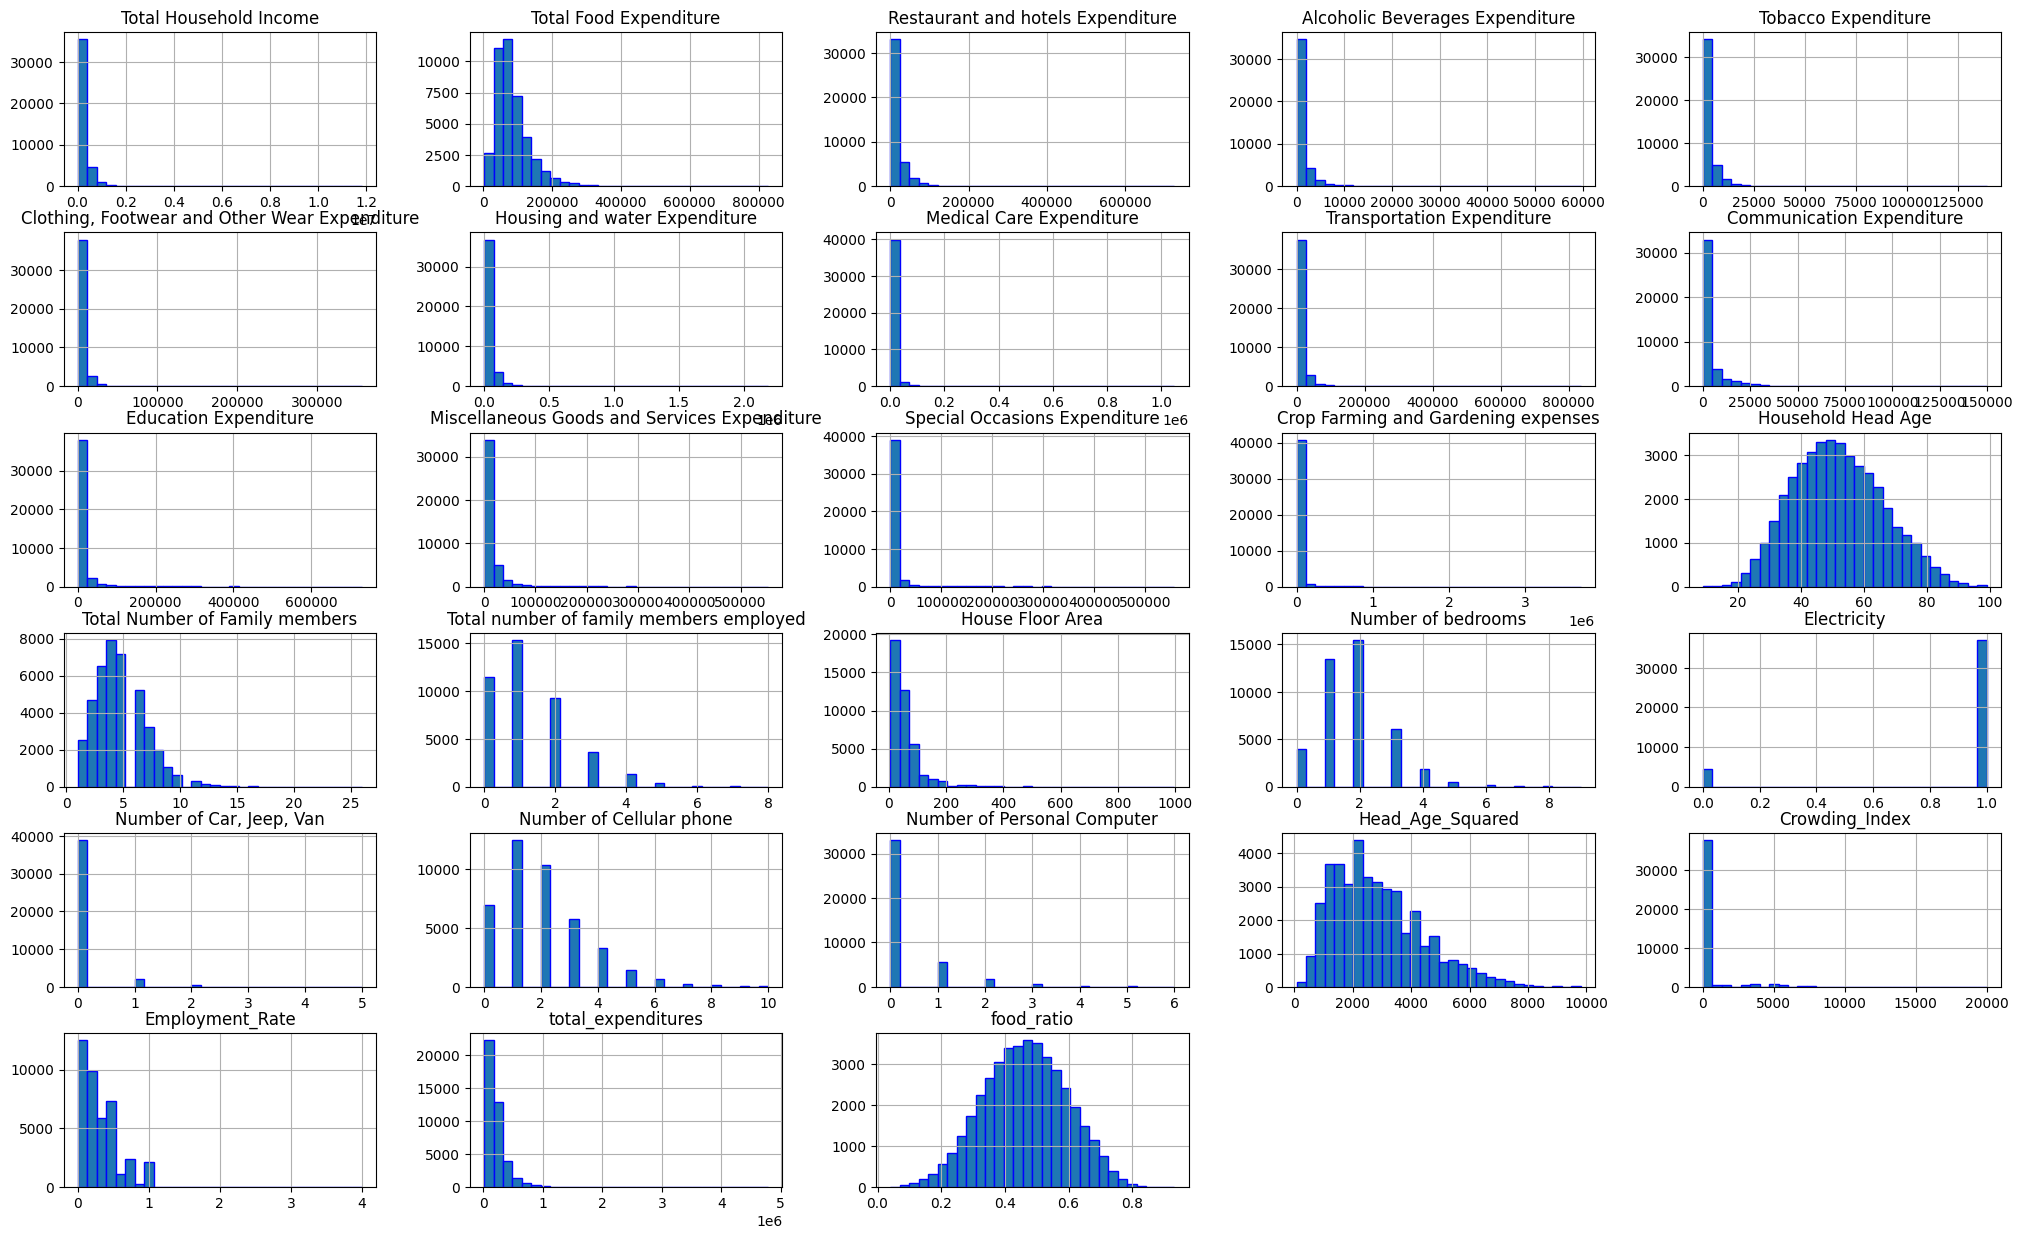

In [ ]:
df.hist(figsize=(25, 15), bins=30, edgecolor='blue')

we checked the distribution of our target feature (‘Total Household Income’) and we noticed that the distribution is not equally divided

<Axes: >

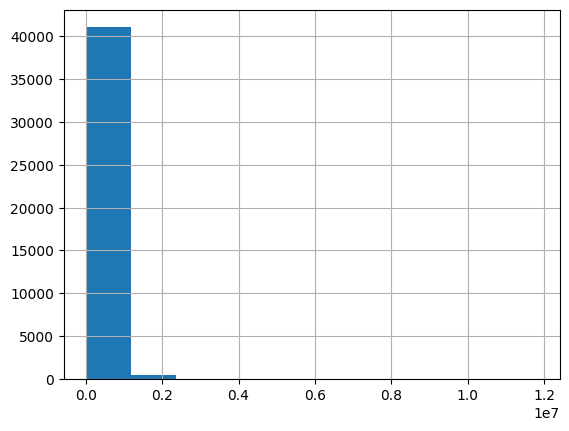

In [ ]:
df['Total Household Income'].hist()

In [ ]:
from sklearn.model_selection import train_test_split

because our target feature's distribution was not equally divided, we decided to split the data to train and test using “stratify” method, as stratification ensures that both the training and testing sets maintain the same proportion of income levels as the original data.

In [ ]:
# Create income categories with quantiles

df['income_cat'] = pd.qcut(df['Total Household Income'], q=5, labels=False, duplicates='drop') # divides the data into 5 equal-sized groups

# Make sure that each bin has approximately the same number of samples
print("Distribution per bin:\n", df['income_cat'].value_counts())

Distribution per bin:
 income_cat
4    8309
0    8309
1    8309
3    8309
2    8308
Name: count, dtype: int64


in order to use the stratification method, we have to bin our data. However, since most households have lower incomes and very few have high incomes, standard binning would not portray the actual distribution, because the high-income bins would be too small. To fix this, we divided the income into quantiles. This method ensures that each bin contains the exact same number of people (20%). This allows us to make sure that both the training and test sets represent all income levels equally.


In [ ]:
#Remove the target variable from X
X = df.drop(['Total Household Income'], axis=1)

#Target Variable
y = df["Total Household Income"]


In addition, we decided to use log transformation on our target variable, ‘Total Household Income’,  since it was quite skewed and wasn't normally distributed.


In [ ]:
# 4. Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=X['income_cat']
)

#Log transformation for target variable
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)


# Since 'income_cat' was created from the Target, keeping it would allow the model to cheat.
# We must drop it from both X_train and X_test before training.
X_train = X_train.drop('income_cat', axis=1)
X_test = X_test.drop('income_cat', axis=1)



In [ ]:
X_train.shape

(33235, 32)

In [ ]:
X_train.head()

,Total Food Expenditure,Main Source of Income,Restaurant and hotels Expenditure,Alcoholic Beverages Expenditure,Tobacco Expenditure,"Clothing, Footwear and Other Wear Expenditure",Housing and water Expenditure,Medical Care Expenditure,Transportation Expenditure,Communication Expenditure,...,Number of bedrooms,Electricity,"Number of Car, Jeep, Van",Number of Cellular phone,Number of Personal Computer,Head_Age_Squared,Crowding_Index,Employment_Rate,total_expenditures,food_ratio
24341,104597,Enterpreneurial Activities,4560,0,21720,5930,34638,1875,4776,2862,...,1,0,0,1,0,1600,9.990010,0.000000,225506,0.463832
23213,80848,Other sources of Income,13548,1470,2470,2450,6720,536,402,60,...,1,1,0,0,0,1156,5.994006,0.166667,118772,0.680699
33182,104599,Enterpreneurial Activities,0,0,0,1560,23040,174,6360,1650,...,1,0,0,2,0,1849,6.993007,0.000000,278996,0.374912
19323,39845,Enterpreneurial Activities,10870,2080,5430,700,9468,63,13758,390,...,2,1,0,1,0,2704,0.999500,0.500000,85824,0.464264
28806,101967,Wage/Salaries,15600,180,1212,2765,25080,522,15360,2232,...,2,1,0,3,0,3025,3.998001,0.375000,183898,0.554476


In [ ]:
X_train.describe()

,Total Food Expenditure,Restaurant and hotels Expenditure,Alcoholic Beverages Expenditure,Tobacco Expenditure,"Clothing, Footwear and Other Wear Expenditure",Housing and water Expenditure,Medical Care Expenditure,Transportation Expenditure,Communication Expenditure,Education Expenditure,...,Number of bedrooms,Electricity,"Number of Car, Jeep, Van",Number of Cellular phone,Number of Personal Computer,Head_Age_Squared,Crowding_Index,Employment_Rate,total_expenditures,food_ratio
count,33235.000000,33235.000000,33235.000000,33235.000000,33235.000000,3.323500e+04,3.323500e+04,33235.000000,33235.000000,33235.000000,...,33235.000000,33235.00000,33235.000000,33235.000000,33235.000000,33235.000000,33235.000000,33235.000000,3.323500e+04,33235.000000
mean,85170.710576,15526.152971,1087.641613,2287.384203,4979.178426,3.852695e+04,7.221114e+03,11874.426598,4113.980021,7449.160042,...,1.789920,0.89156,0.082925,1.907387,0.314428,2842.454100,412.063772,0.295362,2.099682e+05,0.462395
std,51706.637597,23815.961437,2212.181106,3924.722678,7639.581332,5.399827e+04,2.710938e+04,19186.102563,7317.871015,21082.581192,...,1.111674,0.31094,0.351557,1.560874,0.743232,1525.460989,1437.607063,0.273416,1.764418e+05,0.130083
min,3704.000000,0.000000,0.000000,0.000000,0.000000,1.950000e+03,0.000000e+00,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,100.000000,0.111099,0.000000,9.941000e+03,0.040019
25%,50922.000000,1928.000000,0.000000,0.000000,1365.000000,1.306800e+04,3.000000e+02,2400.000000,558.000000,0.000000,...,1.000000,1.00000,0.000000,1.000000,0.000000,1681.000000,1.499250,0.000000,1.034245e+05,0.370648
50%,72879.000000,7310.000000,270.000000,260.000000,2735.000000,2.302800e+04,1.140000e+03,6042.000000,1512.000000,880.000000,...,2.000000,1.00000,0.000000,2.000000,0.000000,2601.000000,2.498751,0.250000,1.593100e+05,0.462832
75%,105852.000000,19945.000000,1292.500000,3150.000000,5600.000000,4.603500e+04,4.730000e+03,13854.000000,3954.000000,4100.000000,...,2.000000,1.00000,0.000000,3.000000,0.000000,3721.000000,4.995005,0.500000,2.565530e+05,0.554479
max,791848.000000,725296.000000,59592.000000,73881.000000,356750.000000,2.188560e+06,1.049275e+06,601890.000000,149940.000000,731000.000000,...,9.000000,1.00000,5.000000,10.000000,6.000000,9801.000000,15000.000000,4.000000,4.366103e+06,0.924217


array([[<Axes: title={'center': 'Total Food Expenditure'}>,
        <Axes: title={'center': 'Restaurant and hotels Expenditure'}>,
        <Axes: title={'center': 'Alcoholic Beverages Expenditure'}>,
        <Axes: title={'center': 'Tobacco Expenditure'}>,
        <Axes: title={'center': 'Clothing, Footwear and Other Wear Expenditure'}>],
       [<Axes: title={'center': 'Housing and water Expenditure'}>,
        <Axes: title={'center': 'Medical Care Expenditure'}>,
        <Axes: title={'center': 'Transportation Expenditure'}>,
        <Axes: title={'center': 'Communication Expenditure'}>,
        <Axes: title={'center': 'Education Expenditure'}>],
       [<Axes: title={'center': 'Miscellaneous Goods and Services Expenditure'}>,
        <Axes: title={'center': 'Special Occasions Expenditure'}>,
        <Axes: title={'center': 'Crop Farming and Gardening expenses'}>,
        <Axes: title={'center': 'Household Head Age'}>,
        <Axes: title={'center': 'Total Number of Family members'}

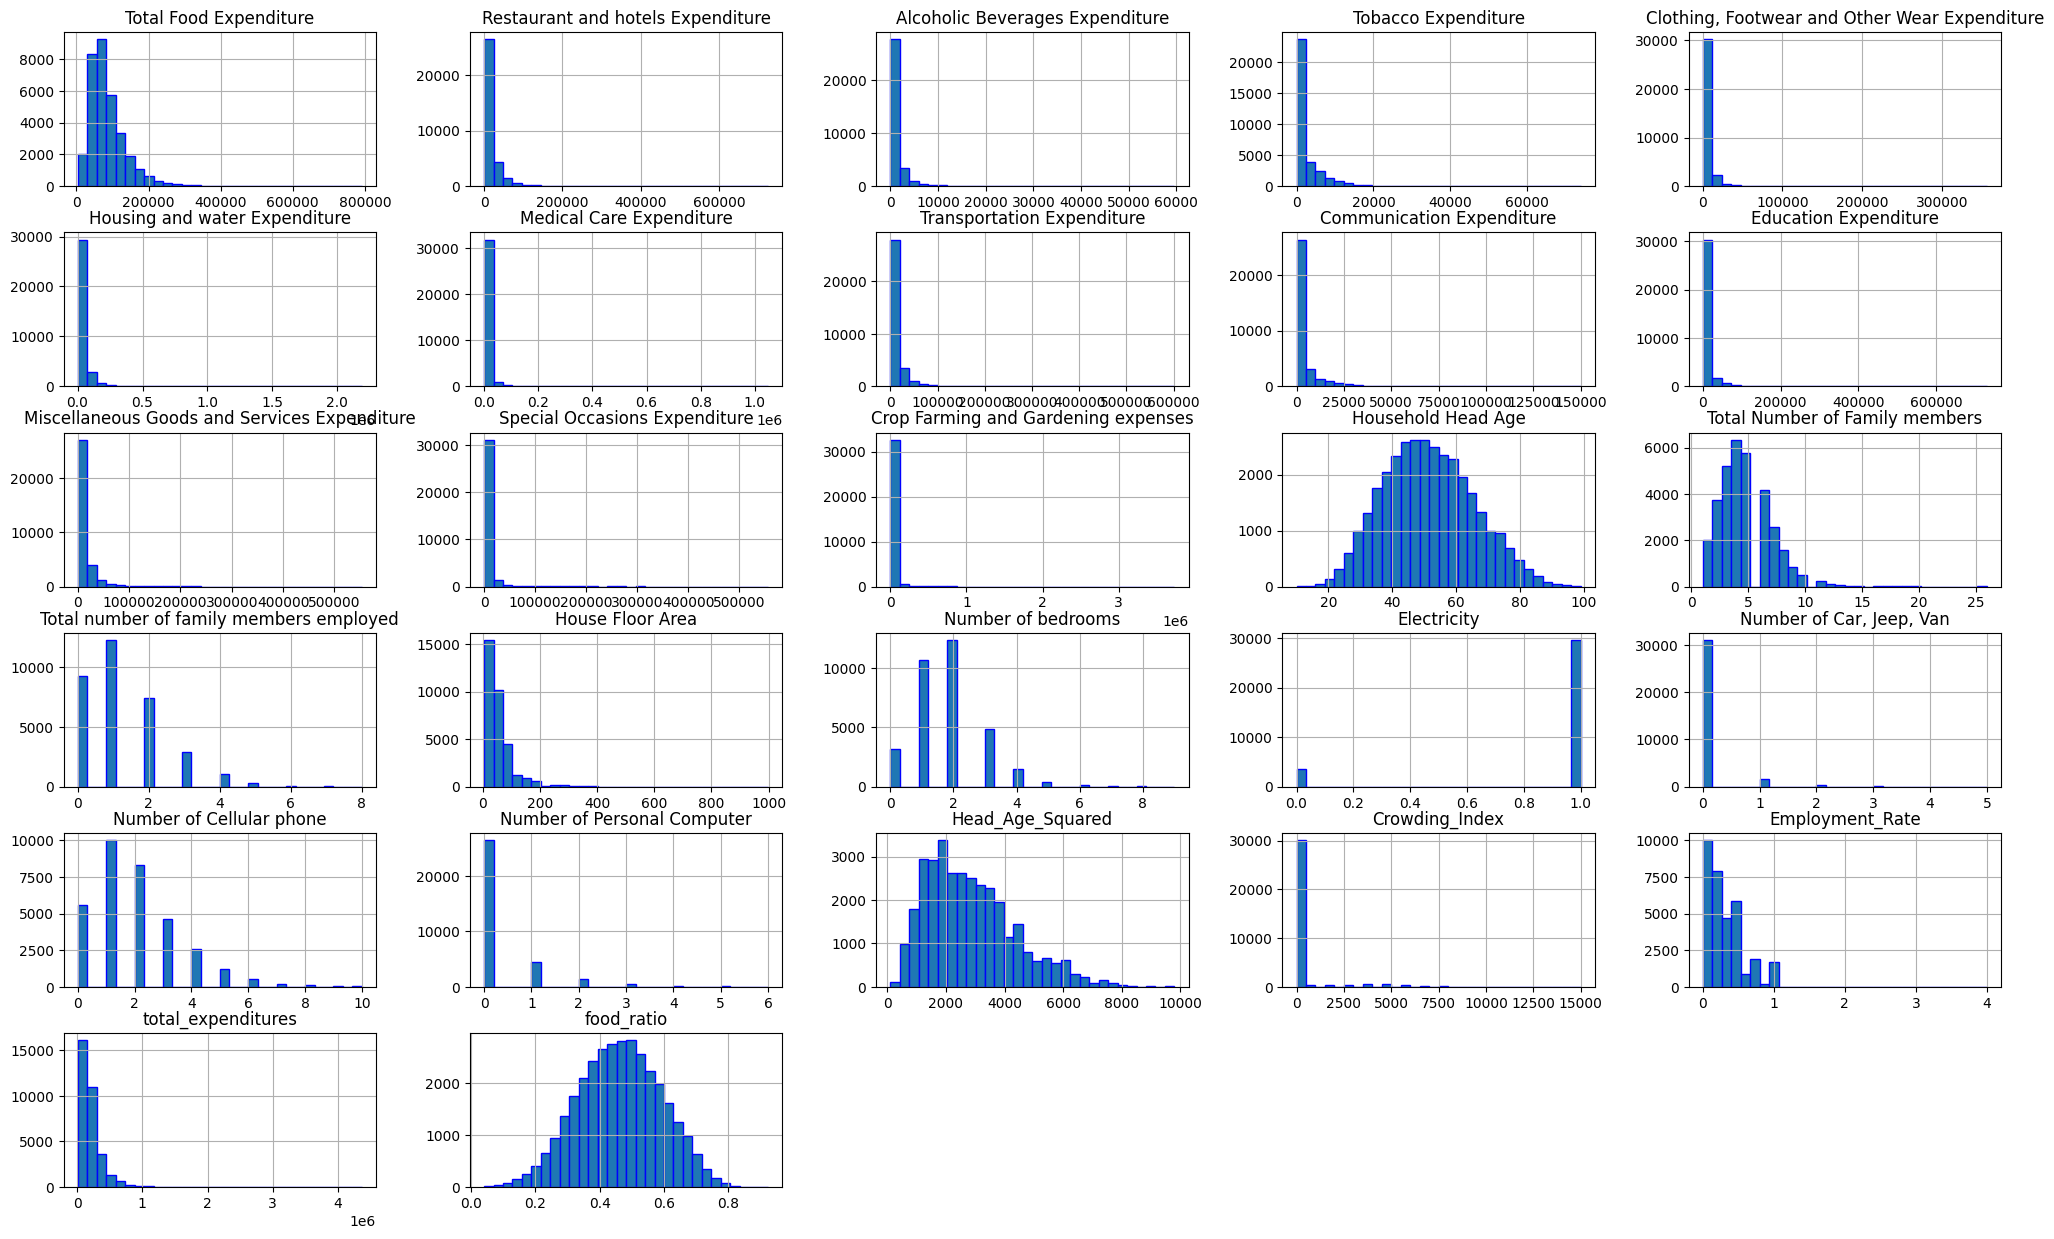

In [ ]:
X_train.hist(figsize=(25, 15), bins=30, edgecolor='blue')

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33235 entries, 24341 to 17735
Data columns (total 32 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Total Food Expenditure                         33235 non-null  int64  
 1   Main Source of Income                          33235 non-null  object 
 2   Restaurant and hotels Expenditure              33235 non-null  int64  
 3   Alcoholic Beverages Expenditure                33235 non-null  int64  
 4   Tobacco Expenditure                            33235 non-null  int64  
 5   Clothing, Footwear and Other Wear Expenditure  33235 non-null  int64  
 6   Housing and water Expenditure                  33235 non-null  int64  
 7   Medical Care Expenditure                       33235 non-null  int64  
 8   Transportation Expenditure                     33235 non-null  int64  
 9   Communication Expenditure                      3323

we noticed that we have a significant number of NA’s in the “Household Head Occupation” column, and that it is the only column in which we have missing values.

In order to determine which type of missingness we are dealing with, we investigated the relationship between the ‘Household Head Job or Business Indicator’ and the missing values in ‘Household Head Occupation’, because we suspected that the missing values in ‘Household Head Occupation’ actually represented unemployed individuals.


In [ ]:
#Ensure 'Household Head Occupation' is null for people marked with'No Job/Business'
no_job_null_check = X_train[X_train['Household Head Job or Business Indicator'] == 'No Job/Business']['Household Head Occupation'].count()

print(no_job_null_check)

0


As can be seen above, in order to test our suspicion, we counted how many individuals were marked as 'No Job/Business' under the ‘Household Head Job or Business Indicator’, but still had a recorded occupation under the  ‘Household Head Occupation’ column. As shown in the code output, the result was 0.


 because the values are missing specifically since the head of the household does not have a job, we can coclude that we deal with MNAR missingness.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression


Regarding the 'Household Head Occupation' feature, since we concluded that we are dealing with MNAR missingness, we decided that instead of treating these as errors or filling them with the Mode, we will fill these missing values with a new category labeled 'Unemployed'.


In our pipeline, we divided our predictors to 4 categories:

Special Categorical: Household Head Occupation- As seen before, missing values here indicate that the person does not have a job, so we used constant imputation to specifically fill them with "Unemployed". We then applied One-Hot Encoding.

In [ ]:
# Defining categories of features

# Special Categorical: Occupation (we want to fill it's NA's with 'Unemployed')
occupation_feature = ['Household Head Occupation']







Standard Categorical Features- For these general text categories, we used Mode Imputation. Finally, One-Hot Encoding was applied.

In [ ]:
# Categorical: Fill with Mode
other_categorical_features = [
    'Electricity',
    'Main Source of Income',
    'Household Head Sex',
    'Household Head Highest Grade Completed',
    'Household Head Job or Business Indicator']


Skewed Numerical Features- These variables have a "long tail" of extreme high values, so we applied a log transformation with Robust Scaler and median imputation because they are highly resistant to any remaining extreme outliers.







In [ ]:
# Numerical Features (Skewed -> Log + Robust scaling)
skewed_features = [
    'Total Food Expenditure',
    'Medical Care Expenditure',
    'Communication Expenditure',
    'Education Expenditure',
    'Special Occasions Expenditure',
    'House Floor Area',
    'Crowding_Index',
    'food_ratio',
    'Tobacco Expenditure',
    'Miscellaneous Goods and Services Expenditure',
    'Employment_Rate',
    'Number of Cellular phone',
    'Restaurant and hotels Expenditure',
    'Alcoholic Beverages Expenditure',
    'Clothing, Footwear and Other Wear Expenditure',
    'Housing and water Expenditure',
    'Transportation Expenditure',
    'Crop Farming and Gardening expenses'
]

Normal Numerical Features - These variables followed a symmetric curve, or they were discrete variables without a significant amount of outliers so we simply applied a Standard Scaler to center the values and ensure all features are on the same mathematical scale.

In [ ]:
# Numerical Features (Normal -> Standard scaling)
normal_features = [
    'Household Head Age',
    'Total Number of Family members',
    'Number of bedrooms',
    'Head_Age_Squared'
]


In [ ]:
# Pipeline

# Occupation
occupation_transformer = Pipeline(steps=[
    # strategy='constant' allows us to choose a specific fill_value
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unemployed')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Categorical (Mode Imputation)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Skewed Numerical Pipeline
skewed_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, validate=False)),
    ('scaler', RobustScaler())
])

# Normal Numerical Pipeline
normal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('occupation', occupation_transformer, occupation_feature),
        ('cat', categorical_transformer, other_categorical_features),
        ('skewed', skewed_transformer, skewed_features),
        ('normal', normal_transformer, normal_features)
    ],
    remainder='drop'  #Every column we didn't use will be dropped and won't cause an error
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

Our five models

In order to choose the best model, we evaluated five different models using 5-Fold cross validation.

Linear Regression: Used as our baseline model to test for simple, linear relationships between household characteristics and total income.

In [ ]:
# 1) Linear Regression
print("\nModel: Linear Regression")

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_scores = cross_val_score(lr_pipeline, X_train, y_train_log, cv=5, scoring='r2', n_jobs=1)

print(f"Mean R^2 Score: {lr_scores.mean():.4f}")
print(f"Stability (Std): {lr_scores.std():.4f}")



Model: Linear Regression
Mean R^2 Score: 0.8740
Stability (Std): 0.0041


Linear Regression with PCA: Included to fulfill the PCA requirement. Since our dataset contains many continuous variables related to household expenditures that might be highly correlated, we applied a PCA approach to reduce dimensionality and eliminate noise before feeding the data into the regression model.

In [ ]:
# 2) Linear Regression with PCA
from sklearn.decomposition import PCA
print("\nModel: Linear Regression With PCA")
pca_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=0.95)),
    ('model', LinearRegression())
])

pca_scores = cross_val_score(pca_pipeline, X_train, y_train_log, cv=5, scoring='r2', n_jobs=1)
print(f"Mean R^2 Score: {pca_scores.mean():.4f}")
print(f"Stability (Std): {pca_scores.std():.4f}")



Model: Linear Regression With PCA
Mean R^2 Score: 0.8623
Stability (Std): 0.0030


K-Nearest Neighbors (KNN): Evaluating whether households with similar scaled features (like expenditures) have similar income levels.

In [ ]:
# 3) K-Nearest Neighbors (KNN)

print("\nModel: K-Nearest Neighbors (KNN)")

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KNeighborsRegressor())
])

knn_scores = cross_val_score(knn_pipeline, X_train, y_train_log, cv=5, scoring='r2', n_jobs=1)

print(f"Mean R^2 Score: {knn_scores.mean():.4f}")
print(f"Stability (Std): {knn_scores.std():.4f}")


Model: K-Nearest Neighbors (KNN)
Mean R^2 Score: 0.8103
Stability (Std): 0.0046


Random Forest: Selected to fulfill the ensemble model requirement. It combines multiple independent decision trees, which significantly reduces overfitting and increases the stability of our predictions.

In [ ]:
# 4) Random Forest
print("\nModel: Random Forest (Ensemble)")

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

rf_scores = cross_val_score(rf_pipeline, X_train, y_train_log, cv=5, scoring='r2', n_jobs=-1)


print(f"Mean R^2 Score: {rf_scores.mean():.4f}")
print(f"Stability (Std): {rf_scores.std():.4f}")


Model: Random Forest (Ensemble)
Mean R^2 Score: 0.8797
Stability (Std): 0.0024


Decision Tree: Included to capture non linear patterns and complex interactions within the data. It works by splitting the dataset into branches based on hierarchical rules, allowing it to model flexible relationships without assuming a strictly linear correlation.

In [ ]:
# 5) Decision Tree
print("\nModel: Decision Tree")

dt_pipeline = Pipeline(steps=[
('preprocessor', preprocessor),
('model', DecisionTreeRegressor(random_state=42))
])

dt_scores = cross_val_score(dt_pipeline, X_train, y_train_log, cv=5, scoring='r2', n_jobs=1)

print(f"Mean R^2 Score: {dt_scores.mean():.4f}")
print(f"Stability (Std): {dt_scores.std():.4f}")


Model: Decision Tree
Mean R^2 Score: 0.7476
Stability (Std): 0.0052


After comparing the five models, we selected the Random Forest as our final model because it achieved the highest Mean R^2 score of 0.8797 and demonstrated the highest stability with the lowest standard deviation of 0.0024.



In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score

**Improvemet Stages**

First, we optimized our winning model (Random Forest) using Hyperparameter Tuning and using random search. We chose to use Random Search rather than Grid Search primarily because of the large size of our dataset.

In [ ]:
# improvement step 1: hyper-parameter tuning

param_dist_simple = {
    'model__n_estimators': [50, 100, 200], # Num of trees
    'model__max_depth': [5, 10, 15],
    'model__min_samples_split': [2 ,5, 10]
    }

random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist_simple,
    n_iter=5,
    cv=5,
    scoring='r2',
    verbose=3,
    random_state=42
)

random_search_rf.fit(X_train, y_train_log)

# finding the best parameters
print(f"Best Parameters: {random_search_rf.best_params_}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV 1/5] END model__max_depth=5, model__min_samples_split=10, model__n_estimators=200;, score=0.832 total time= 1.4min
[CV 2/5] END model__max_depth=5, model__min_samples_split=10, model__n_estimators=200;, score=0.831 total time= 1.4min
[CV 3/5] END model__max_depth=5, model__min_samples_split=10, model__n_estimators=200;, score=0.832 total time= 1.5min
[CV 4/5] END model__max_depth=5, model__min_samples_split=10, model__n_estimators=200;, score=0.827 total time= 1.4min
[CV 5/5] END model__max_depth=5, model__min_samples_split=10, model__n_estimators=200;, score=0.837 total time= 1.4min
[CV 1/5] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=100;, score=0.873 total time= 1.2min
[CV 2/5] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=100;, score=0.874 total time= 1.2min
[CV 3/5] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=100;, score=0.876 total t

In [ ]:
# Extract the best model from the search
best_rf_model = random_search_rf.best_estimator_

# Make predictions using the best model
y_pred = best_rf_model.predict(X_test)

# Calculate r^2 and rmse
r2_test = r2_score(y_test_log, y_pred)
rmse_test = np.sqrt(mean_squared_error(y_test_log, y_pred))

print(f"R^2 Score on Test: {r2_test:.4f}")
print(f"RMSE on Test: {rmse_test:.2f}")

R^2 Score on Test: 0.8764
RMSE on Test: 0.27


It is important to note that in regards to the RMSE, while the model was trained on a logarithmic scale, reporting the RMSE only in log units is not practical. A logarithmic RMSE makes it difficult to understand the actual error in terms of real world meaning. Therefore, we transformed our predictions back to the original scale to evaluate the model's true performance.

In [ ]:
# RMSE on Log Scale
rmse_test_log = np.sqrt(mean_squared_error(y_test_log, y_pred))

# Reverse the log transformation to see the error in actual currency
y_test_original = np.expm1(y_test_log)
y_pred_original = np.expm1(y_pred)

# RMSE Original Scale
rmse_test_original = np.sqrt(mean_squared_error(y_test_original, y_pred_original))

print(f"R^2 Score on Test: {r2_test:.4f}")
print(f"RMSE (Log Scale): {rmse_test_log:.4f}")
print(f"RMSE (Original Scale - Actual Currency): {rmse_test_original:,.2f}")

R^2 Score on Test: 0.8764
RMSE (Log Scale): 0.2687
RMSE (Original Scale - Actual Currency): 114,207.51


In [ ]:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np


As the secong stage of improvement, we implemented stacking, using our optimized Random Forest as the base model and a Ridge Regression model. This structure allows the Ridge model to act as a supervisor, learning from the Random Forest’s errors to provide refined final predictions.

In [ ]:
# Improvement Step 2: Stacking (Random Forest + Ridge)

# Define our Random Forest as the base model
base_estimators = [
    ('rf', RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_split=5, random_state=42))
]

stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=5
)

# Integrate the stacking ensemble into the main pipeline
stacking_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', stacking_model)
])

# Train and evaluate the Stacking pipeline
stacking_pipeline.fit(X_train, y_train_log)
y_pred_stack_log = stacking_pipeline.predict(X_test)

r2_stack = r2_score(y_test_log, y_pred_stack_log)
print(f"R^2 Score (After Stacking with Ridge): {r2_stack:.4f}")

# Final real-world evaluation (Actual values) for the winning model

best_pred_log = y_pred_stack_log
best_pred_original = np.expm1(best_pred_log)


R^2 Score (After Stacking with Ridge): 0.8765


In [ ]:
# Calculate RMSE on the Logarithmic scale
rmse_stack_log = np.sqrt(mean_squared_error(y_test_log, y_pred_stack_log))
print(f"RMSE (Log Scale): {rmse_stack_log:.4f}")


best_pred_log = y_pred_stack_log
best_pred_original = np.expm1(best_pred_log)

# We also need to reverse the log transformation for the actual test values
y_test_original = np.expm1(y_test_log)

# Calculate RMSE on the Original scale
rmse_stack_original = np.sqrt(mean_squared_error(y_test_original, best_pred_original))
print(f"RMSE (Original Scale - Actual Currency): {rmse_stack_original:,.2f}")

RMSE (Log Scale): 0.2686
RMSE (Original Scale - Actual Currency): 112,939.70


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

We implemented a tuned bagging strategy, limiting each tree to 80% random sampling to increase diversity and prevent overfitting. Enabling OOB evaluation allowed the model to self-test during training on excluded data points, ensuring a more robust and reliable final model.

In [ ]:
# Improvement Step 3 : bagging + OOB


# Define the model with Tuned Bagging and OOB configurations
tuned_rf_model = RandomForestRegressor(
    n_estimators=100,
    bootstrap=True, #Enables Bagging (sampling with replacement)
    max_samples=0.8, #Each tree gets 80% of the data
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Create a new pipeline
rf_bagging_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', tuned_rf_model)
])

# Train the model
rf_bagging_pipeline.fit(X_train, y_train_log)

oob_score_val = rf_bagging_pipeline.named_steps['model'].oob_score_
print(f"OOB Score (Internal Validation): {oob_score_val:.4f}")

# Predict and calculate the final R^2
y_pred_bagging_log = rf_bagging_pipeline.predict(X_test)
r2_bagging = r2_score(y_test_log, y_pred_bagging_log)

print(f"R^2 Score on Test Set: {r2_bagging:.4f}")

# RMSE (Log Scale & Original Scale)
rmse_log = np.sqrt(mean_squared_error(y_test_log, y_pred_bagging_log))
print(f"RMSE (Log Scale): {rmse_log:.4f}")

# Reverse the log transformation to see the error in actual currency
y_test_original = np.expm1(y_test_log)
y_pred_bagging_original = np.expm1(y_pred_bagging_log)

rmse_original = np.sqrt(mean_squared_error(y_test_original, y_pred_bagging_original))
print(f"RMSE (Original Scale - Actual Currency): {rmse_original:,.2f}")

OOB Score (Internal Validation): 0.8784
R^2 Score on Test Set: 0.8775
RMSE (Log Scale): 0.2675
RMSE (Original Scale - Actual Currency): 115,033.65


Although the Bagging model slightly increased RMSE, it achieved a higher R^2 score, indicating a better overall fit. The RMSE increase likely comes from high income outliers rather than reduced accuracy. Therefore, we selected the Bagging model as our final and most robust improvement stage.

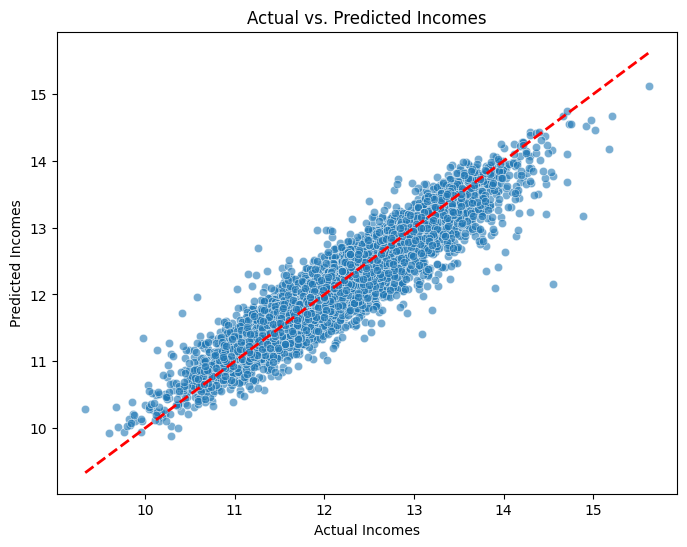

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_log, y=y_pred_bagging_log, alpha=0.6)
plt.plot([y_test_log.min(), y_test_log.max()], [y_test_log.min(), y_test_log.max()], 'r--', lw=2)
plt.xlabel('Actual Incomes')
plt.ylabel('Predicted Incomes')
plt.title('Actual vs. Predicted Incomes')
plt.show()

Residual VS Predicted plot

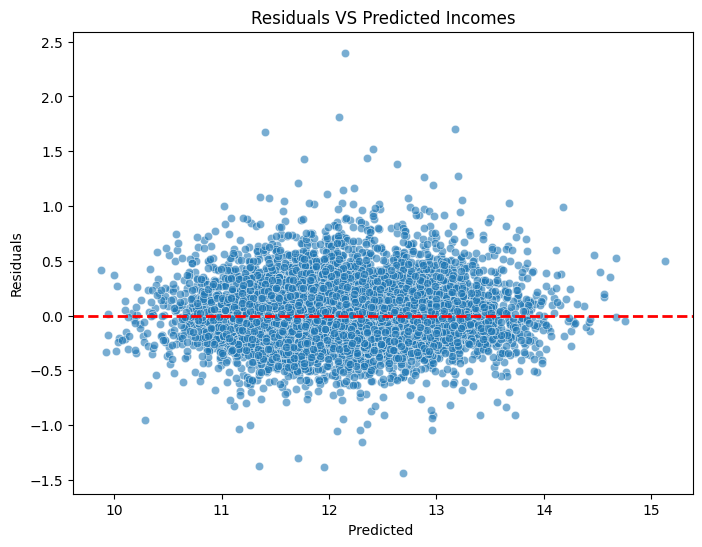

In [ ]:
residuals = y_test_log - y_pred_bagging_log

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred_bagging_log, y=residuals, alpha=0.6)

plt.axhline(y=0, color='r', linestyle='--', lw=2)

plt.xlabel('Predicted ')
plt.ylabel('Residuals')
plt.title('Residuals VS Predicted Incomes')
plt.show()

Residuals Distribution plot

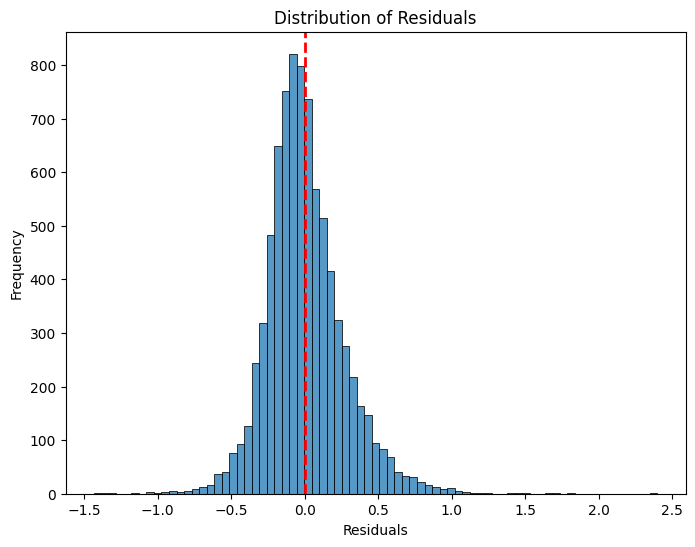

In [ ]:
# Set the size of the figure
plt.figure(figsize=(8, 6))

# Plot the distribution of the residuals with a KDE (Kernel Density Estimate) curve
sns.histplot(residuals, bins=75)

# Add a vertical red dashed line at zero to represent the ideal center (zero error)
plt.axvline(x=0, color='red', linestyle='--', lw=2)

# Add labels and a title
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

# Display the plot
plt.show()

Building TreeExplainer for Random Forest...
Calculating SHAP values...


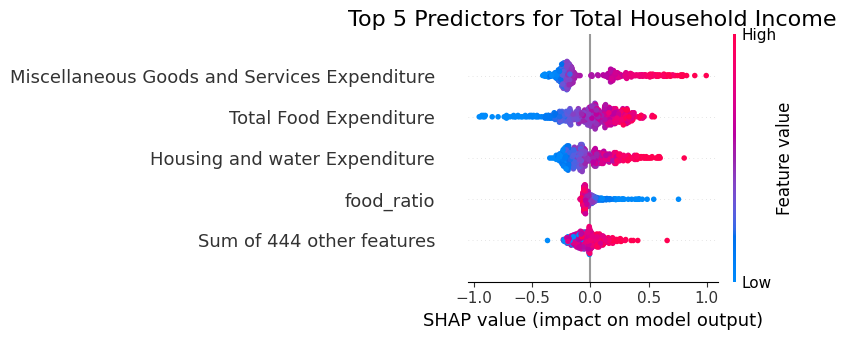

In [ ]:
!pip -q install shap

import shap


# ensure objects exist
assert "rf_bagging_pipeline" in globals(), "Pipeline not found. Run the training cell first."
assert "X_test" in globals() and "y_test_log" in globals(), "Test data not found."

# Extract model and preprocessor from our pipeline
rf_model = rf_bagging_pipeline.named_steps['model']
preprocessor = rf_bagging_pipeline.named_steps['preprocessor']

# Transform the test data through the preprocessor
X_test_processed = preprocessor.transform(X_test)
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Extract and CLEAN original feature names
clean_names = []

# Occupation features
occupation_ohe_encoder = preprocessor.named_transformers_['occupation'].named_steps['encoder']
clean_names.extend(occupation_ohe_encoder.get_feature_names_out(occupation_feature))

# Other categorical features
cat_ohe_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
clean_names.extend(cat_ohe_encoder.get_feature_names_out(other_categorical_features))

# Skewed numerical features
clean_names.extend(skewed_features)

# Normal numerical features
clean_names.extend(normal_features)

# Create DataFrame with the clean original names
X_test_shap = pd.DataFrame(X_test_processed, columns=clean_names)

# Build the explainer
explainer = shap.TreeExplainer(rf_model)


# We use 500 which is large enough to be statistically representative
MAX_PLOT_N = 500
if len(X_test_shap) > MAX_PLOT_N:
    X_plot = X_test_shap.sample(n=MAX_PLOT_N, random_state=42)
else:
    X_plot = X_test_shap.copy()


shap_values = explainer(X_plot, check_additivity=False)

# SHAP Plot

plt.figure(figsize=(12, 20)) # Increased figure height


shap.plots.beeswarm(shap_values, max_display=5, show=False)

plt.title("Top 5 Predictors for Total Household Income", fontsize=16)
plt.tight_layout()
plt.show()